# 3.2 One-way slab: continuous over beams

A stand-alone wing of the building: slab spanning continuously over beams at 3.5 m centres, panels 8 m long.

**Workflow**

| Step | Check | Reference |
|:--|:--|:--|
| 1 | One-way or two-way: ly/lx > 2 → one-way | EC2 5.3.1(5) |
| 2 | Thickness, cover, effective depth, fire | EC2 4.4.1, EN 1992-1-2 |
| 3 | Actions and ULS combination | EN 1990, EN 1991-1-1 |
| 4 | Moments and shears | EC2 5; coefficients |
| 5 | Bending steel, minimum and maximum | EC2 6.1, 9.2.1.1, 9.3.1.1 |
| 6 | Shear without links | EC2 6.2.2 |
| 7 | Deflection | EC2 7.4.2 |
| 8 | Cracking, spacing, secondary steel, curtailment | EC2 7.3.3, 9.3.1 |

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## Inputs

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `l`, `ly` | Span; panel length | m | ly > 2 l |
| `nspans` | Number of equal spans |  | 3 or more |
| `width` | Full width of the structure | m | > 0 |
| `h` | Slab thickness | mm | > 0 |
| `exposure` | Exposure class |  | `"X0"`, `"XC1"` to `"XC4"`, `"XD1"` to `"XD3"`, `"XS1"` to `"XS3"` |
| `R` | Fire rating | minutes | 30, 60, 90, 120, 180, 240 |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |
| `finishes`, `qk`, `part` | Finishes, imposed load, partitions (characteristic) | kN/m² | self-weight is added for you |
| `psi2` | Quasi-permanent factor |  | 0.3 for homes and offices |
| `bars` | `(bar, spacing)` at each location | mm | 8, 10, 12, 16, 20, 25, 32 |

Keep the location names in `bars` exactly as written.

In [2]:
# INPUTS: edit only this cell, then run the cells below it
l, ly, nspans, width = 3.5, 8.0, 4, 16.0     # span (m), panel length (m), number of equal spans, width of the bay strip (m), nspans >= 3
h, exposure, R = 150, "XC1", 60
fck, fyk = 30, 500                          # N/mm²
finishes, qk, part, psi2 = 1.5, 3.0, 0.8, 0.3     # kN/m², kN/m², kN/m², -
bars = {"end span": (10, 200), "first support": (10, 200), "interior span": (10, 250), "interior support": (10, 250)}      # (bar mm, spacing mm) to verify

In [3]:
s = Sheet("Continuous one-way slab", element=f"Wing slab, {nspans} × {l} m")
phi_max = max(p for p, _ in bars.values())
D.materials(s, fck, fyk, BRIEF["ndp"])
s.let("l_x", l, "m"); s.let("l_y", ly, "m"); s.calc("r", "l_y/l_x"); s.check("r", ">=", 2.0, "one-way spanning, ly/lx > 2", "EC2 5.3.1(5)")
s.show("Type of slab")
D.floor_actions(s, h, finishes, qk, part); s.show("Actions")
c = D.cover(s, exposure, phi_max)
s.let("phi", phi_max, "mm"); s.calc("d", "h - c_nom - phi/2", "mm"); s.show("Effective depth")
D.fire_slab(s, R, h, c + min(p for p, _ in bars.values()) / 2)
s.note("The 20% redistribution below exceeds 15%, so each span is treated as simply supported in fire (EN 1992-1-2 5.7.3(2)). Table 5.8 column 3 was used, so the check above already covers this."); s.show()

## Continuous one-way slab

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Wing slab, 4 × 3.5 m

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Type of slab

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $l_{x}$ | $l_{x} = 3.5$ m |
|  | $l_{y}$ | $l_{y} = 8$ m |
|  | $r = \dfrac{l_{y}}{l_{x}}$<br>$\quad = \dfrac{8}{3.5}$ | $\mathbf{r = 2.286}$ |
| EC2 5.3.1(5) | **Check:** one-way spanning, ly/lx > 2<br>$r = 2.286 \ge 2$  | ✅ **PASS**<br>ratio 0.88 |


### Actions

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Slab thickness: $h$ | $h = 150$ mm |
| EN 1991-1-1 Table A.1 | Reinforced concrete, 24 + 1: $\gamma_{rc}$ | $\gamma_{rc} = 25$ kN/m³ |
| EN 1991-1-1 5.2 | $g_{k,self} = \dfrac{\gamma_{rc}\,h}{1000}$<br>$\quad = \dfrac{25\times 150}{1000}$ | $\mathbf{g_{k,self} = 3.75}$ kN/m²<br><small>(= 3750 Pa)</small> |
|  | Finishes and services (project input): $g_{k,fin}$ | $g_{k,fin} = 1.5$ kN/m²<br><small>(= 1500 Pa)</small> |
|  | $g_{k} = g_{k,self} + g_{k,fin}$<br>$\quad = 3.75 + 1.5$ | $\mathbf{g_{k} = 5.25}$ kN/m²<br><small>(= 5250 Pa)</small> |
| EN 1991-1-1 Table 6.2 | Imposed load, category B: $q_{k,1}$ | $q_{k,1} = 3$ kN/m²<br><small>(= 3000 Pa)</small> |
| EN 1991-1-1 6.3.1.2(8) | Movable partitions (1.0 to 2.0 kN/m wall): $q_{k,2}$ | $q_{k,2} = 0.8$ kN/m²<br><small>(= 800 Pa)</small> |
|  | $q_{k} = q_{k,1} + q_{k,2}$<br>$\quad = 3 + 0.8$ | $\mathbf{q_{k} = 3.8}$ kN/m²<br><small>(= 3800 Pa)</small> |
| EN 1990 Table A1.2(B) | $\gamma_{G}$ | $\gamma_{G} = 1.35$  |
| EN 1990 Table A1.2(B) | $\gamma_{Q}$ | $\gamma_{Q} = 1.5$  |
| EN 1990 Exp. (6.10) | $n_{Ed} = \gamma_{G}\,g_{k} + \gamma_{Q}\,q_{k}$<br>$\quad = 1.35\times 5.25 + 1.5\times 3.8$ | $\mathbf{n_{Ed} = 12.79}$ kN/m²<br><small>(= 12788 Pa)</small> |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 10$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
| EC2 Exp. (4.1), (4.2) | $c_{req} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{10;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Effective depth

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $d = h - c_{nom} - \dfrac{\phi}{2}$<br>$\quad = 150 - 25 - \dfrac{10}{2}$ | $\mathbf{d = 120}$ mm |


### Fire resistance

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Axis distance to the lower bar: $a_{prov}$ | $a_{prov} = 30$ mm |
| EN 1992-1-2 Table 5.8 | REI 60: $a_{req}$ | $a_{req} = 20$ mm |
| EN 1992-1-2 Table 5.8 | REI 60: $h_{s,min}$ | $h_{s,min} = 80$ mm |
| EN 1992-1-2 5.7 | **Check:** fire – slab thickness<br>$h = 150 \ge h_{s,min} = 80$ mm | ✅ **PASS**<br>ratio 0.53 |
| EN 1992-1-2 5.7 | **Check:** fire – axis distance<br>$a_{prov} = 30 \ge a_{req} = 20$ mm | ✅ **PASS**<br>ratio 0.67 |


| Reference | Calculation | Output |
|:--|:--|:--|
|  | The 20% redistribution below exceeds 15%, so each span is treated as simply supported in fire (EN 1992-1-2 5.7.3(2)). Table 5.8 column 3 was used, so the check above already covers this. |  |


## Can the simplified load case and coefficients be used?

UK NA to EC2 5.1.3, option (c): analyse with **all spans loaded** and reduce the support moments by 20% when three conditions hold.

In [4]:
s.let("A_bay", l * width, "m²", "Area of a bay (span × full width of the structure)"); s.check("A_bay", ">=", 30.0, "bay area exceeds 30 m²", "NA 5.1.3(1)P c)1)")
s.calc("r_QG", "q_k/g_k"); s.check("r_QG", "<=", 1.25, "Qk / Gk", "NA 5.1.3(1)P c)2)")
s.let("q_k_1", qk, "kN/m²", "Imposed load excluding partitions"); s.check("q_k_1", "<=", 5.0, "Qk excluding partitions", "NA 5.1.3(1)P c)3)")
s.show("Conditions")

### Conditions

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Area of a bay (span × full width of the structure): $A_{bay}$ | $A_{bay} = 56$ m² |
| NA 5.1.3(1)P c)1) | **Check:** bay area exceeds 30 m²<br>$A_{bay} = 56 \ge 30$ m² | ✅ **PASS**<br>ratio 0.54 |
|  | $r_{QG} = \dfrac{q_{k}}{g_{k}}$<br>$\quad = \dfrac{3.8}{5.25}$ | $\mathbf{r_{QG} = 0.724}$ |
| NA 5.1.3(1)P c)2) | **Check:** Qk / Gk<br>$r_{QG} = 0.724 \le 1.25$  | ✅ **PASS**<br>ratio 0.58 |
| NA 5.1.3(1)P c)3) | **Check:** Qk excluding partitions<br>$q_{k,1} = 3 \le 5$ kN/m²<br><small>(= 3000 ≤ 5000 Pa)</small> | ✅ **PASS**<br>ratio 0.60 |


## Moments: coefficients, verified by the three-moment equation

Coefficients: BS 8110-1 Table 3.12, simple outer support, approximately equal spans (3.5.2.4). They already include the 20% redistribution. F = n·l, with n from EN 1990 (1.35G + 1.5Q) in place of the BS 8110 factors.

**M / (F·l)**

| Location | Coefficient | Three-moment, supports − 20% |
|:--|:-:|:-:|
| Near middle of end span | 0.086 | 0.0858 |
| First interior support | -0.086 | -0.0857 |
| Middle of interior span | 0.063 | 0.054 |
| Interior support | -0.063 | -0.0571 |


| Reference | Calculation | Output |
|:--|:--|:--|
|  | Total load on one span<br>$F = n_{Ed}\,l_{x}$<br>$\quad = 12.79\times 3.5$ | $\mathbf{F = 44.76}$ kN/m |
|  | **Check:** coefficients cover the NA 5.1.3 c) analysis | ✅ **PASS** |


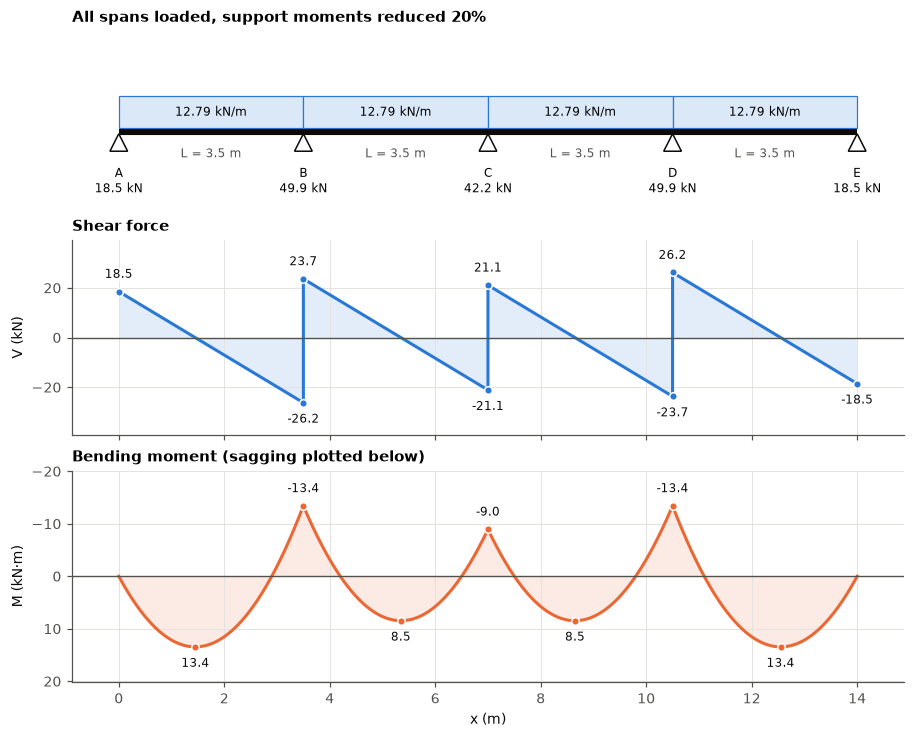

### Design moments and shears (per metre)

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 Table 3.12 | $M_{end} = 0.086\,F\,l_{x}$<br>$\quad = 0.086\times 44.76\times 3.5$ | $\mathbf{M_{end} = 13.47}$ kN·m/m |
| BS 8110-1 Table 3.12 | $M_{first} = 0.086\,F\,l_{x}$<br>$\quad = 0.086\times 44.76\times 3.5$ | $\mathbf{M_{first} = 13.47}$ kN·m/m |
| BS 8110-1 Table 3.12 | $M_{int} = 0.063\,F\,l_{x}$<br>$\quad = 0.063\times 44.76\times 3.5$ | $\mathbf{M_{int} = 9.869}$ kN·m/m |
| BS 8110-1 Table 3.12 | $M_{intsup} = 0.063\,F\,l_{x}$<br>$\quad = 0.063\times 44.76\times 3.5$ | $\mathbf{M_{intsup} = 9.869}$ kN·m/m |
| BS 8110-1 Table 3.12 | Shear at first interior support<br>$V_{first} = 0.6\,F$<br>$\quad = 0.6\times 44.76$ | $\mathbf{V_{first} = 26.85}$ kN/m |
| BS 8110-1 Table 3.12 | $V_{out} = 0.4\,F$<br>$\quad = 0.4\times 44.76$ | $\mathbf{V_{out} = 17.9}$ kN/m |


In [5]:
s.calc("F", "n_Ed*l_x", "kN/m", "", "Total load on one span")
cb = ContinuousBeam([Span(l, [UDL(s["n_Ed"])])] * nspans); cb.three_moment()
el = cb.M_sup.copy()
cb.M_sup = el * 0.8; cb.diagrams()
Fl = s["F"] * l
mid = [m.max() for m in cb.M]
rows = [["Near middle of end span", 0.086, mid[0] / Fl], ["First interior support", -0.086, cb.M_sup[1] / Fl], ["Middle of interior span", 0.063, mid[1] / Fl], ["Interior support", -0.063, cb.M_sup[2] / Fl]]
table([[a, b, round(x, 4)] for a, b, x in rows], ["Location", "Coefficient", "Three-moment, supports − 20%"], "M / (F·l)")
s.verdict(all(abs(b) >= abs(x) - 0.001 for _, b, x in rows), "coefficients cover the NA 5.1.3 c) analysis")
s.show()
P.continuous(cb, "All spans loaded, support moments reduced 20%")
for nme, co in (("M_end", .086), ("M_first", .086), ("M_int", .063), ("M_intsup", .063)):
    s.calc(nme, f"{co}*F*l_x", "kN·m/m", "BS 8110-1 Table 3.12")
s.calc("V_first", "0.6*F", "kN/m", "BS 8110-1 Table 3.12", "Shear at first interior support"); s.calc("V_out", "0.4*F", "kN/m", "BS 8110-1 Table 3.12"); s.show("Design moments and shears (per metre)")

## Bending (δ = 0.8)

In [6]:
d = s["d"]; res = {}
for where, m in (("end span", "M_end"), ("first support", "M_first"), ("interior span", "M_int"), ("interior support", "M_intsup")):
    As, _ = D.flexure(s, s[m], 1000, d, delta=0.8, label=f"({where})")
    res[where] = (As, D.slab_bars(s, *bars[where], h, label=where))
    s.show(where.capitalize())

### End span

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 0.8$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 Exp. (3.21) | Stress-block strength factor, fck ≤ 50: $\eta$ | $\eta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{0.8 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.4}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.4\times \left(1 - \dfrac{0.8\times 0.4}{2}\right)$ | $\mathbf{K' = 0.152}$ |
|  | Design moment (end span): $M_{Ed}$ | $M_{Ed} = 13.47$ kN·m |
|  | $b$ | $b = 1000$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{13.47\times 10^{6}}{1000\times 120^{2}\times 30}$ | $\mathbf{K = 0.03118}$ |
| EC2 5.5(4) | **Check:** singly reinforced (end span)<br>$K = 0.03118 \le K' = 0.152$  | ✅ **PASS**<br>ratio 0.20 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{120}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.03118\times 30}{1\times 17}}\right);\; 0.95\times 120\right\}$ | $\mathbf{z = 114}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(120 - 114\right)}{0.8}$ | $\mathbf{x = 15}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{13.47\times 10^{6}}{434.8\times 114}$ | $\mathbf{A_{s,req} = 271.8}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 1000$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 1000\times 120;\; 0.0013\times 1000\times 120\right\}$ | $\mathbf{A_{s,min} = 180.7}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{271.8;\; 180.7\right\}$ | $\mathbf{A_{s,req} = 271.8}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 200$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 10^{2}}{4}\times 1000}{200}$ | $\mathbf{A_{s,prov} = 392.7}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided end span<br>$A_{s,prov} = 392.7 \ge A_{s,req} = 271.8$ mm²/m | ✅ **PASS**<br>ratio 0.69 |
| EC2 9.3.1.1(3) | Principal bars, zone of maximum moment: $s_{max}$ | $s_{max} = 250$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing end span<br>$s_{prov} = 200 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 0.80 |
| EC2 9.2.1.1(3) | $A_{s,max} = 0.04\times 1000\,h$<br>$\quad = 0.04\times 1000\times 150$ | $\mathbf{A_{s,max} = 6000}$ mm²/m |
| EC2 9.2.1.1(3) | **Check:** maximum steel end span<br>$A_{s,prov} = 392.7 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.07 |
|  | **PROVIDE: H10 @ 200 mm end span (393 mm²/m)** | 🟦 **H10 @ 200 mm end span (393 mm²/m)** |


### First support

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | **Check:** singly reinforced (first support)<br>$K = 0.03118 \le K' = 0.152$  | ✅ **PASS**<br>ratio 0.20 |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{13.47\times 10^{6}}{434.8\times 114}$ | $\mathbf{A_{s,req} = 271.8}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{271.8;\; 180.7\right\}$ | $\mathbf{A_{s,req} = 271.8}$ mm² |
| EC2 6.1, 9.3.1.1 | **Check:** area provided first support<br>$A_{s,prov} = 392.7 \ge A_{s,req} = 271.8$ mm²/m | ✅ **PASS**<br>ratio 0.69 |
| EC2 9.3.1.1(3) | **Check:** maximum spacing first support<br>$s_{prov} = 200 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 0.80 |
| EC2 9.2.1.1(3) | **Check:** maximum steel first support<br>$A_{s,prov} = 392.7 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.07 |
|  | **PROVIDE: H10 @ 200 mm first support (393 mm²/m)** | 🟦 **H10 @ 200 mm first support (393 mm²/m)** |


### Interior span

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment (interior span): $M_{Ed}$ | $M_{Ed} = 9.869$ kN·m |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{9.869\times 10^{6}}{1000\times 120^{2}\times 30}$ | $\mathbf{K = 0.02284}$ |
| EC2 5.5(4) | **Check:** singly reinforced (interior span)<br>$K = 0.02284 \le K' = 0.152$  | ✅ **PASS**<br>ratio 0.15 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{120}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.02284\times 30}{1\times 17}}\right);\; 0.95\times 120\right\}$ | $\mathbf{z = 114}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{9.869\times 10^{6}}{434.8\times 114}$ | $\mathbf{A_{s,req} = 199.1}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{199.1;\; 180.7\right\}$ | $\mathbf{A_{s,req} = 199.1}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 250$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 10^{2}}{4}\times 1000}{250}$ | $\mathbf{A_{s,prov} = 314.2}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided interior span<br>$A_{s,prov} = 314.2 \ge A_{s,req} = 199.1$ mm²/m | ✅ **PASS**<br>ratio 0.63 |
| EC2 9.3.1.1(3) | **Check:** maximum spacing interior span<br>$s_{prov} = 250 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 1.00 |
| EC2 9.2.1.1(3) | **Check:** maximum steel interior span<br>$A_{s,prov} = 314.2 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.05 |
|  | **PROVIDE: H10 @ 250 mm interior span (314 mm²/m)** | 🟦 **H10 @ 250 mm interior span (314 mm²/m)** |


### Interior support

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | **Check:** singly reinforced (interior support)<br>$K = 0.02284 \le K' = 0.152$  | ✅ **PASS**<br>ratio 0.15 |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{9.869\times 10^{6}}{434.8\times 114}$ | $\mathbf{A_{s,req} = 199.1}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{199.1;\; 180.7\right\}$ | $\mathbf{A_{s,req} = 199.1}$ mm² |
| EC2 6.1, 9.3.1.1 | **Check:** area provided interior support<br>$A_{s,prov} = 314.2 \ge A_{s,req} = 199.1$ mm²/m | ✅ **PASS**<br>ratio 0.63 |
| EC2 9.3.1.1(3) | **Check:** maximum spacing interior support<br>$s_{prov} = 250 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 1.00 |
| EC2 9.2.1.1(3) | **Check:** maximum steel interior support<br>$A_{s,prov} = 314.2 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.05 |
|  | **PROVIDE: H10 @ 250 mm interior support (314 mm²/m)** | 🟦 **H10 @ 250 mm interior support (314 mm²/m)** |


## Shear, deflection, cracking, secondary steel

### Shear

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design shear first interior support: $V_{Ed}$ | $V_{Ed} = 26.85$ kN/m |
|  | $b_{w}$ | $b_{w} = 1000$ mm |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 392.7$ mm² |
| EC2 6.2.2(1), NA | $C_{Rd,c} = \dfrac{0.18}{\gamma_{c}}$<br>$\quad = \dfrac{0.18}{1.5}$ | $\mathbf{C_{Rd,c} = 0.12}$ |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{120}};\; 2\right\}$ | $\mathbf{k = 2}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{392.7}{1000\times 120};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00327}$ |
| EC2 Exp. (6.3N) | $v_{min} = 0.035\,k^{1.5}\,\sqrt{f_{ck}}$<br>$\quad = 0.035\times 2^{1.5}\times \sqrt{30}$ | $\mathbf{v_{min} = 0.542}$ N/mm²<br><small>(= 0.542 MPa)</small> |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 2\times \left(100\times 0.00327\times 30\right)^{1/3};\; 0.542\right\}\times 1000\times 120}{1000}$ | $\mathbf{V_{Rd,c} = 65.07}$ kN |
| EC2 6.2.1(3), 6.2.1(4) | **Check:** shear, no links needed first interior support<br>$V_{Ed} = 26.85 \le V_{Rd,c} = 65.07$ kN/m | ✅ **PASS**<br>ratio 0.41 |


### Deflection, end span (critical)

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 7.4N / NA.5 | Structural system: end span: $K_{sys}$ | $K_{sys} = 1.3$  |
|  | Effective span: $l_{eff}$ | $l_{eff} = 3500$ mm |
| EC2 7.4.2(2) | 10⁻³ √fck: $\rho_{0}$ | $\rho_{0} = 0.00548$  |
|  | Steel required for ULS at mid-span: $A_{s,ult}$ | $A_{s,ult} = 271.8$ mm² |
| EC2 7.4.2(2) | $\rho = \dfrac{A_{s,ult}}{b\,d}$<br>$\quad = \dfrac{271.8}{1000\times 120}$ | $\mathbf{\rho = 0.00226}$ |
| EC2 Exp. (7.16a) | Basic l/d<br>$N_{basic} = K_{sys}\,\left(11 + \dfrac{1.5\,\sqrt{f_{ck}}\,\rho_{0}}{\rho} + 3.2\,\sqrt{f_{ck}}\,\left(\dfrac{\rho_{0}}{\rho} - 1\right)^{1.5}\right)$<br>$\quad = 1.3\times \left(11 + \dfrac{1.5\times \sqrt{30}\times 0.00548}{0.00226} + 3.2\times \sqrt{30}\times \left(\dfrac{0.00548}{0.00226} - 1\right)^{1.5}\right)$ | $\mathbf{N_{basic} = 78.61}$ |
| EC2 7.4.2(2) | Flanged section, b_f/b_w = 1.00: $F_{1}$ | $F_{1} = 1$  |
| EC2 7.4.2(2) | Span > 7 m with brittle partitions: $F_{2}$ | $F_{2} = 1$  |
|  | $A_{s,prov}$ | $A_{s,prov} = 392.7$ mm² |
| NA Table NA.5 Note 5 | Cap on the steel-stress factor: $F_{cap}$ | $F_{cap} = 1.5$  |
| EC2 Exp. (7.17), NA Note 5 | $F_{3} = \min\left\{\dfrac{500}{\dfrac{f_{yk}\,A_{s,ult}}{A_{s,prov}}};\; F_{cap}\right\}$<br>$\quad = \min\left\{\dfrac{500}{\dfrac{500\times 271.8}{392.7}};\; 1.5\right\}$ | $\mathbf{F_{3} = 1.445}$ |
| NA Table NA.5 Note 6 | Absolute limit 40K: $N_{abs}$ | $N_{abs} = 40$  |
| EC2 7.4.2(2), NA | $N_{allow} = \min\left\{N_{basic}\,F_{1}\,F_{2}\,F_{3};\; N_{abs}\,K_{sys}\right\}$<br>$\quad = \min\left\{78.61\times 1\times 1\times 1.445;\; 40\times 1.3\right\}$ | $\mathbf{N_{allow} = 52}$ |
|  | $N_{actual} = \dfrac{l_{eff}}{d}$<br>$\quad = \dfrac{3500}{120}$ | $\mathbf{N_{actual} = 29.17}$ |
| EC2 7.4.2 | **Check:** deflection (span/depth)<br>$N_{actual} = 29.17 \le N_{allow} = 52$  | ✅ **PASS**<br>ratio 0.56 |


### Cracking

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 7.3.3(1) | Slab ≤ 200 mm thick without axial tension and detailed to EC2 9.3: no specific crack-control measures needed. |  |
| EC2 7.3.3(1) | **Check:** crack control | ✅ **PASS** |


### Secondary reinforcement

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $A_{s,main}$ | $A_{s,main} = 392.7$ mm²/m |
| EC2 9.3.1.1(2), 9.2.1.1(1) | $A_{s,req} = \max\left\{0.2\,A_{s,main};\; A_{s,min}\right\}$<br>$\quad = \max\left\{0.2\times 392.7;\; 180.7\right\}$ | $\mathbf{A_{s,req} = 180.7}$ mm²/m |
|  | Bar diameter: $\phi$ | $\phi = 8$ mm |
|  | Spacing: $s_{prov}$ | $s_{prov} = 275$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 8^{2}}{4}\times 1000}{275}$ | $\mathbf{A_{s,prov} = 182.8}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided secondary<br>$A_{s,prov} = 182.8 \ge A_{s,req} = 180.7$ mm²/m | ✅ **PASS**<br>ratio 0.99 |
| EC2 9.3.1.1(3) | Secondary bars, zone of maximum moment: $s_{max}$ | $s_{max} = 400$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing secondary<br>$s_{prov} = 275 \le s_{max} = 400$ mm | ✅ **PASS**<br>ratio 0.69 |
| EC2 9.2.1.1(3) | **Check:** maximum steel secondary<br>$A_{s,prov} = 182.8 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.03 |
|  | **PROVIDE: H8 @ 275 mm secondary (183 mm²/m)** | 🟦 **H8 @ 275 mm secondary (183 mm²/m)** |
| EC2 9.3.1.2(2) | Top steel at the outer support, 25% of span moment (15% is the EC2 minimum at an end support)<br>$M_{top} = 0.25\,M_{end}$<br>$\quad = 0.25\times 13.47$ | $\mathbf{M_{top} = 3.368}$ kN·m/m |


### Outer support

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | Design moment (outer support): $M_{Ed}$ | $M_{Ed} = 3.368$ kN·m |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{3.368\times 10^{6}}{1000\times 120^{2}\times 30}$ | $\mathbf{K = 0.0078}$ |
| EC2 5.5(4) | **Check:** singly reinforced (outer support)<br>$K = 0.0078 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.05 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{120}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.0078\times 30}{1\times 17}}\right);\; 0.95\times 120\right\}$ | $\mathbf{z = 114}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{3.368\times 10^{6}}{434.8\times 114}$ | $\mathbf{A_{s,req} = 67.95}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{180.7;\; 180.7\right\}$ | $\mathbf{A_{s,req} = 180.7}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 250$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 8^{2}}{4}\times 1000}{250}$ | $\mathbf{A_{s,prov} = 201.1}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided top, outer support<br>$A_{s,prov} = 201.1 \ge A_{s,req} = 180.7$ mm²/m | ✅ **PASS**<br>ratio 0.90 |
| EC2 9.3.1.1(3) | Principal bars, zone of maximum moment: $s_{max}$ | $s_{max} = 250$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing top, outer support<br>$s_{prov} = 250 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 1.00 |
| EC2 9.2.1.1(3) | **Check:** maximum steel top, outer support<br>$A_{s,prov} = 201.1 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.03 |
|  | **PROVIDE: H8 @ 250 mm top, outer support (201 mm²/m)** | 🟦 **H8 @ 250 mm top, outer support (201 mm²/m)** |


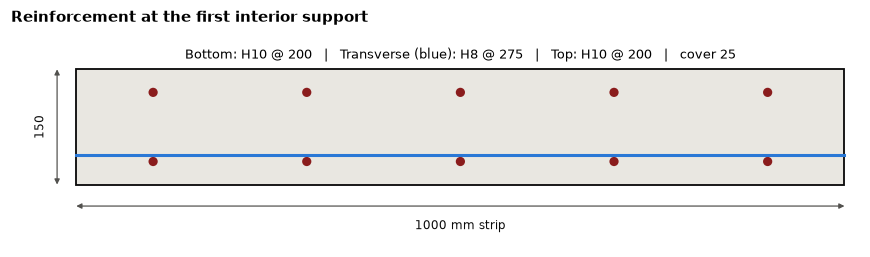

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| one-way spanning, ly/lx > 2 | EC2 5.3.1(5) | 0.88 | ✅ PASS |
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| fire – slab thickness | EN 1992-1-2 5.7 | 0.53 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 5.7 | 0.67 | ✅ PASS |
| bay area exceeds 30 m² | NA 5.1.3(1)P c)1) | 0.54 | ✅ PASS |
| Qk / Gk | NA 5.1.3(1)P c)2) | 0.58 | ✅ PASS |
| Qk excluding partitions | NA 5.1.3(1)P c)3) | 0.60 | ✅ PASS |
| coefficients cover the NA 5.1.3 c) analysis |  | – | ✅ PASS |
| singly reinforced (end span) | EC2 5.5(4) | 0.20 | ✅ PASS |
| area provided end span | EC2 6.1, 9.3.1.1 | 0.69 | ✅ PASS |
| maximum spacing end span | EC2 9.3.1.1(3) | 0.80 | ✅ PASS |
| maximum steel end span | EC2 9.2.1.1(3) | 0.07 | ✅ PASS |
| singly reinforced (first support) | EC2 5.5(4) | 0.20 | ✅ PASS |
| area provided first support | EC2 6.1, 9.3.1.1 | 0.69 | ✅ PASS |
| maximum spacing first support | EC2 9.3.1.1(3) | 0.80 | ✅ PASS |
| maximum steel first support | EC2 9.2.1.1(3) | 0.07 | ✅ PASS |
| singly reinforced (interior span) | EC2 5.5(4) | 0.15 | ✅ PASS |
| area provided interior span | EC2 6.1, 9.3.1.1 | 0.63 | ✅ PASS |
| maximum spacing interior span | EC2 9.3.1.1(3) | 1.00 | ✅ PASS |
| maximum steel interior span | EC2 9.2.1.1(3) | 0.05 | ✅ PASS |
| singly reinforced (interior support) | EC2 5.5(4) | 0.15 | ✅ PASS |
| area provided interior support | EC2 6.1, 9.3.1.1 | 0.63 | ✅ PASS |
| maximum spacing interior support | EC2 9.3.1.1(3) | 1.00 | ✅ PASS |
| maximum steel interior support | EC2 9.2.1.1(3) | 0.05 | ✅ PASS |
| shear, no links needed first interior support | EC2 6.2.1(3), 6.2.1(4) | 0.41 | ✅ PASS |
| deflection (span/depth) | EC2 7.4.2 | 0.56 | ✅ PASS |
| crack control | EC2 7.3.3(1) | – | ✅ PASS |
| area provided secondary | EC2 6.1, 9.3.1.1 | 0.99 | ✅ PASS |
| maximum spacing secondary | EC2 9.3.1.1(3) | 0.69 | ✅ PASS |
| maximum steel secondary | EC2 9.2.1.1(3) | 0.03 | ✅ PASS |
| singly reinforced (outer support) | EC2 5.5(4) | 0.05 | ✅ PASS |
| area provided top, outer support | EC2 6.1, 9.3.1.1 | 0.90 | ✅ PASS |
| maximum spacing top, outer support | EC2 9.3.1.1(3) | 1.00 | ✅ PASS |
| maximum steel top, outer support | EC2 9.2.1.1(3) | 0.03 | ✅ PASS |

**All checks pass.**

In [7]:
D.shear_slab(s, s["V_first"], d, res["first support"][1], "first interior support"); s.show("Shear")
D.deflection(s, l * 1000, d, 1000, *res["end span"], "end span"); s.show("Deflection, end span (critical)")
D.crack(s, s["g_k"], s["q_k"], psi2, *res["end span"], bars["end span"][1], h, n_uls="slab"); s.show("Cracking")
s.let("A_s_main", res["end span"][1], "mm²/m"); s.calc("A_s_req", "max(0.2*A_s_main, A_s_min)", "mm²/m", "EC2 9.3.1.1(2), 9.2.1.1(1)")
p2, s2 = D.pick_slab(s["A_s_req"], h, main=False, phis=(8, 10)); D.slab_bars(s, p2, s2, h, main=False, label="secondary")
s.calc("M_top", "0.25*M_end", "kN·m/m", "EC2 9.3.1.2(2)", "Top steel at the outer support, 25% of span moment (15% is the EC2 minimum at an end support)"); s.show("Secondary reinforcement")
D.flexure(s, s["M_top"], 1000, d, label="(outer support)"); pt, st = D.pick_slab(s["A_s_req"], h, phis=(8, 10)); D.slab_bars(s, pt, st, h, label="top, outer support"); s.show("Outer support")
P.slab_section(h, c, bars["end span"], bars["first support"], (p2, s2), "Reinforcement at the first interior support")
s.summary()

## Load passed to the supporting beams

Each metre of an interior beam receives the two adjoining slab shears: 0.6F + 0.5F at the first interior beam, 0.5F + 0.5F at other interior beams, 0.4F at the edge beam.

In [8]:
s = Sheet("Slab reactions on beams", element="Wing slab")
s.let("F", Fl / l, "kN/m"); s.calc("w_edge", "0.4*F", "kN/m", "BS 8110-1 Table 3.12"); s.calc("w_first", "(0.6 + 0.5)*F", "kN/m", "BS 8110-1 Table 3.12"); s.calc("w_int", "(0.5 + 0.5)*F", "kN/m", "BS 8110-1 Table 3.12"); s.show()

## Slab reactions on beams

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Wing slab

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $F$ | $F = 44.76$ kN/m |
| BS 8110-1 Table 3.12 | $w_{edge} = 0.4\,F$<br>$\quad = 0.4\times 44.76$ | $\mathbf{w_{edge} = 17.9}$ kN/m |
| BS 8110-1 Table 3.12 | $w_{first} = \left(0.6 + 0.5\right)\,F$<br>$\quad = \left(0.6 + 0.5\right)\times 44.76$ | $\mathbf{w_{first} = 49.23}$ kN/m |
| BS 8110-1 Table 3.12 | $w_{int} = \left(0.5 + 0.5\right)\,F$<br>$\quad = \left(0.5 + 0.5\right)\times 44.76$ | $\mathbf{w_{int} = 44.76}$ kN/m |
